# 08 — Low-margin payment economics

New user-proposed scenario: an approved legitimate payment earns **0.3% of Amount**; an approved fraud loses **100% of Amount**; cancellation earns zero. The 0.3% is an assumed retained contribution margin, not an observed industry fee or dataset outcome. On an Amount of 100, the outcomes are +0.30, −100, or zero. One approved fraud costs the profit from about 333 equal-sized legitimate approvals.

For fraud probability `p`, expected approval profit is `Amount × [0.003 × (1 − p) − p]`. Break-even is `0.003 / 1.003 = 0.002991…`, or **0.2991% fraud probability**. Ties and zero amounts approve. The new margin lowers the acceptable risk even though the fraud-loss fraction itself is unchanged.

This step reprices existing scores and changes the policy threshold without retraining. Stage 07's model, economics, manifest, and final result stay historical. Selection comparisons are development evidence; the consumed evaluation population is used only as a **regression comparison**, with no new independent final-test claim.

In [1]:
from pathlib import Path
import json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MLFLOW_DISABLE_AGENT_HINT="1")
run = subprocess.run([sys.executable, str(root / "scripts/run_low_margin_scenario.py")], cwd=root, env=env, capture_output=True, text=True)
print(run.stdout)
if run.returncode:
    print(run.stderr)
run.check_returncode()

New break-even probability: 0.0029910269 (0.299103%).

selection_development
                           policy  simulated_profit_per_1000  frauds_canceled  legitimate_canceled
                      approve_all                    -28.434                0                    0
      cancel_all_positive_amounts                      0.000               72                42297
                      amount_rule                    -18.146                2                  405
     random_forest_original_20pct                    225.904               60                    8
         random_forest_break_even                    208.330               65                 1377
              logistic_break_even                    227.636               64                  582
              lightgbm_break_even                    238.668               62                   90
random_forest_isotonic_break_even                    223.294               60                   34
               candidate        

In [2]:
report = json.loads((root / "reports/low-margin-scenario.json").read_text())
assert not report["metadata"]["models_refitted"]
assert not report["metadata"]["independent_final_evaluation"]
print(f"Original threshold: {100 * report['metadata']['original_threshold']:.2f}% fraud probability")
print(f"New break-even: {100 * report['metadata']['break_even_threshold']:.4f}% fraud probability")
examples = np.array([10, 100, 1000, 10000])
display(pd.DataFrame({"Amount": examples, "legitimate_approve_profit": 0.003 * examples,
                      "fraud_approve_profit": -examples, "cancel_profit": np.zeros(len(examples))}))

Original threshold: 20.00% fraud probability
New break-even: 0.2991% fraud probability


,Amount,legitimate_approve_profit,fraud_approve_profit,cancel_profit
0,10,0.03,-10,0.0
1,100,0.30,-100,0.0
2,1000,3.00,-1000,0.0
3,10000,30.00,-10000,0.0


## Development comparison

The existing Random Forest is retained as the scenario reference, regardless of which model leads this new selection table. Compare the previous 20% policy with the new algebraic threshold, the existing logistic and LightGBM scores, the selected isotonic RF mapping, and simple payment policies. No threshold is optimized using labels.

In [3]:
columns = ["policy", "simulated_profit_per_1000", "profit_pct_of_maximum", "frauds_canceled", "legitimate_canceled", "approved_fraud_amount", "forgone_legitimate_margin"]
selection = pd.DataFrame(report["comparisons"]["selection_development"]["results"])
display(selection[columns].round(3).sort_values("simulated_profit_per_1000", ascending=False))
selection_intervals = pd.DataFrame(report["comparisons"]["selection_development"]["uncertainty"]["paired_differences"])
display(selection_intervals.round(3))

,policy,simulated_profit_per_1000,profit_pct_of_maximum,frauds_canceled,legitimate_canceled,approved_fraud_amount,forgone_legitimate_margin
6,lightgbm_break_even,238.668,90.266,62,90,950.35,146.894
5,logistic_break_even,227.636,86.094,64,582,1056.51,511.034
3,random_forest_original_20pct,225.904,85.438,60,8,1561.73,79.668
7,random_forest_isotonic_break_even,223.294,84.451,60,34,1561.73,190.939
4,random_forest_break_even,208.330,78.792,65,1377,941.44,1449.168
1,cancel_all_positive_amounts,0.000,0.000,72,42297,0.00,11272.142
2,amount_rule,-18.146,-6.863,2,405,9740.53,2305.222
0,approve_all,-28.434,-10.754,0,0,12484.34,0.000


,candidate,comparator,profit_difference_per_1000,lower_95,upper_95,conclusion
0,random_forest_break_even,approve_all,236.764,114.553,384.553,positive
1,random_forest_break_even,cancel_all_positive_amounts,208.330,179.238,228.965,positive
2,random_forest_break_even,amount_rule,226.476,133.172,333.215,positive
3,random_forest_break_even,random_forest_original_20pct,-17.574,-35.301,11.990,inconclusive
4,random_forest_break_even,logistic_break_even,-19.306,-51.578,17.361,inconclusive
5,random_forest_break_even,lightgbm_break_even,-30.338,-35.425,-25.667,negative
6,random_forest_break_even,random_forest_isotonic_break_even,-14.964,-31.594,14.390,inconclusive


## Reused evaluation benchmark

This table uses cached scores from stage 07. It recomputes payoffs and actions on those same payments, so it is a regression/sensitivity comparison. LightGBM and isotonic RF were not scored on stage 07 evaluation and are therefore shown only in the development table above. The original frozen candidate is not replaced by this analysis.

In [4]:
regression = pd.DataFrame(report["comparisons"]["evaluation_regression"]["results"])
display(regression[columns].round(3).sort_values("simulated_profit_per_1000", ascending=False))
regression_intervals = pd.DataFrame(report["comparisons"]["evaluation_regression"]["uncertainty"]["paired_differences"])
display(regression_intervals.round(3))
print("The paired intervals condition on fixed scores and observed pattern groups; repeated scenario analysis is not independent confirmation.")

,policy,simulated_profit_per_1000,profit_pct_of_maximum,frauds_canceled,legitimate_canceled,approved_fraud_amount,forgone_legitimate_margin
4,random_forest_break_even,221.629,81.444,61,1481,687.36,1468.520
3,random_forest_original_20pct,176.782,64.963,54,10,4066.52,4.053
5,logistic_break_even,164.063,60.290,57,558,4054.62,558.945
2,amount_rule,73.375,26.964,2,477,5862.54,2622.873
0,approve_all,56.467,20.750,0,0,9207.30,0.000
1,cancel_all_positive_amounts,0.000,0.000,68,42357,0.00,11618.091


,candidate,comparator,profit_difference_per_1000,lower_95,upper_95,conclusion
0,random_forest_break_even,approve_all,165.162,48.928,313.123,positive
1,random_forest_break_even,cancel_all_positive_amounts,221.629,193.117,240.134,positive
2,random_forest_break_even,amount_rule,148.253,84.590,224.003,positive
3,random_forest_break_even,random_forest_original_20pct,44.847,-34.696,165.075,inconclusive
4,random_forest_break_even,logistic_break_even,57.565,-21.777,177.055,inconclusive


The paired intervals condition on fixed scores and observed pattern groups; repeated scenario analysis is not independent confirmation.


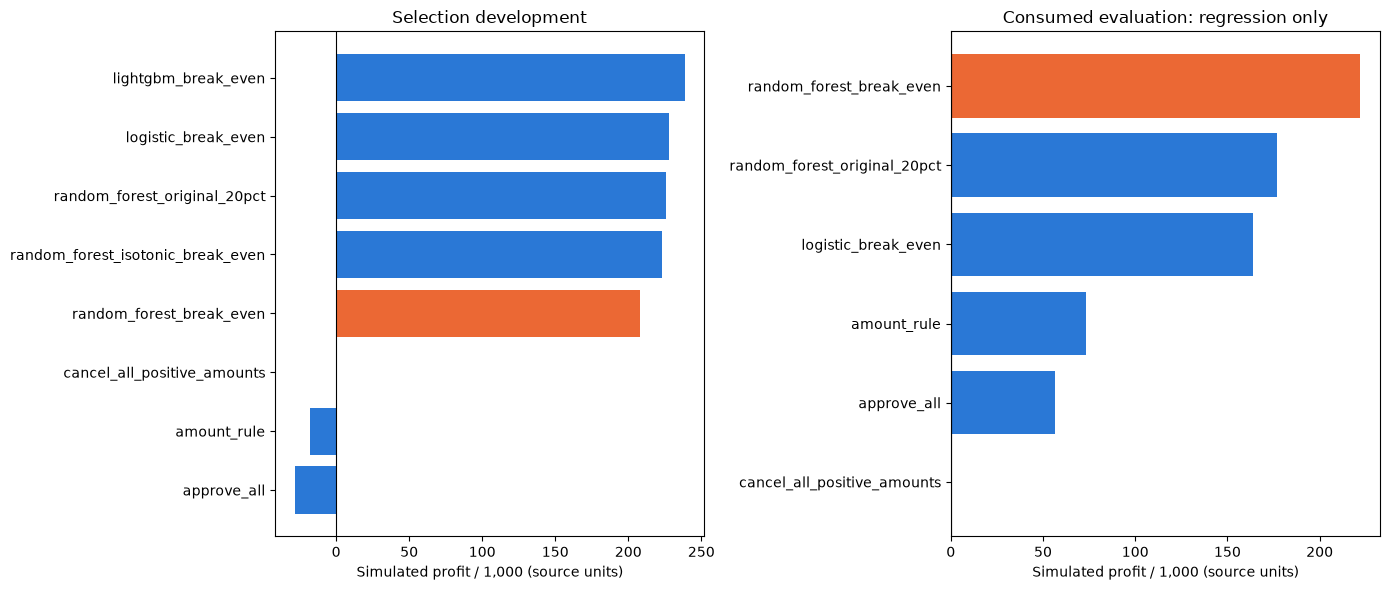

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, frame, title in zip(axes, [selection, regression], ["Selection development", "Consumed evaluation: regression only"]):
    ordered = frame.sort_values("simulated_profit_per_1000")
    colors = ["#eb6834" if name == "random_forest_break_even" else "#2a78d6" for name in ordered.policy]
    ax.barh(ordered.policy, ordered.simulated_profit_per_1000, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=title, xlabel="Simulated profit / 1,000 (source units)")
fig.tight_layout()
fig.savefig(root / "reports/figures/low-margin-policy-comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## Raw Random Forest reliability near the new threshold

A theoretical probability threshold assumes meaningful probabilities. These are uncalibrated tree scores. The table checks their observed fraud fractions in selection bands around the new threshold; counts describe risk frequency, while monetary outcomes also depend on each payment's Amount. The zero-score band can still contain fraud, which a positive score threshold cannot catch.

In [6]:
raw_scores = pd.read_csv(root / "data/processed/experiment-selection-predictions.csv")
rf = raw_scores.loc[raw_scores.model.eq("random_forest")].copy()
threshold = report["metadata"]["break_even_threshold"]
bands = pd.cut(rf.score, bins=[-1e-15, 0, 0.001, threshold, 0.01, 0.05, 0.2, 1.0000001], include_lowest=True)
reliability = rf.groupby(bands, observed=True).agg(payments=("Class", "size"), frauds=("Class", "sum"), mean_score=("score", "mean"))
reliability["observed_fraud_rate"] = reliability.frauds / reliability.payments
display(reliability.round(6))

,payments,frauds,mean_score,observed_fraud_rate
score,,,,
"(-0.001000000000001, 0.0]",39961,6,0.000000,0.000150
"(0.0, 0.001]",30,0,0.000955,0.000000
"(0.001, 0.00299]",1154,1,0.002196,0.000867
"(0.00299, 0.01]",1059,2,0.005168,0.001889
"(0.01, 0.05]",324,4,0.019731,0.012346
"(0.05, 0.2]",32,0,0.082125,0.000000
"(0.2, 1.0]",72,63,0.778177,0.875000


**Interpretation:** With the lower margin, the original stage 07 profit totals no longer describe the new economic hypothesis. LightGBM leads the selection table at the new theoretical threshold. Lowering raw RF's threshold catches more fraud but greatly increases legitimate cancellations, and does not automatically improve selection profit. The consumed evaluation comparison cannot establish a newly validated policy. The next model/policy decision should be made for the agreed retained margin, with calibration near 0.3% risk and fresh labeled evidence; the historical stage 07 freeze remains intact.